In [1]:

# ============================================================
# RIFE + CMAM + CMCL — GOES-19 TEST PATCH EVALUATION
# Checkpoint: epoch_100.pth
#
# Metrics: MSE, PSNR, SSIM, MAE, RMSE, FSIM
# Model import: automatically locate RIFE_CMAM_CMCL.py
# Mode: TEST ONLY — no training or weight updates
# ============================================================

import os
import sys
import time
import math
import importlib
import importlib.util
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

# ============================================================
# FIX MODEL PACKAGE IMPORTS
# Research_RIFE/model/RIFE_CMAM_CMCL.py
# ============================================================

import sys
import importlib
from pathlib import Path

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

RIFE_ROOT = PROJECT_DIR / "Research_RIFE"
MODEL_DIR = RIFE_ROOT / "model"
MODEL_FILE = MODEL_DIR / "RIFE_CMAM_CMCL.py"

if not MODEL_FILE.exists():
    raise FileNotFoundError(
        f"Custom model not found: {MODEL_FILE}"
    )

for required_file in [
    MODEL_DIR / "warplayer.py",
    MODEL_DIR / "IFNet.py",
]:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required model dependency not found: {required_file}"
        )

# Put Research_RIFE first so "from model..." resolves correctly.
sys.path.insert(0, str(RIFE_ROOT))

# Avoid accidentally reusing an unrelated package named "model".
existing_model = sys.modules.get("model")

if existing_model is not None:
    existing_file = getattr(existing_model, "__file__", None)
    existing_path = getattr(existing_model, "__path__", [])

    expected_dir = str(MODEL_DIR.resolve())

    package_matches = (
        existing_file is not None
        and Path(existing_file).resolve().parent == MODEL_DIR.resolve()
    ) or any(
        Path(p).resolve() == MODEL_DIR.resolve()
        for p in existing_path
    )

    if not package_matches:
        # Remove only the conflicting model package and its submodules.
        for name in list(sys.modules):
            if name == "model" or name.startswith("model."):
                del sys.modules[name]

# Import as a package, allowing internal imports to work.
module = importlib.import_module("model.RIFE_CMAM_CMCL")
Model = module.Model

print("Model imported successfully:", Model)
print("Model source:", module.__file__)
print("Model package path:", list(sys.modules["model"].__path__))

# ============================================================
# INITIALIZE MODEL
# ============================================================

model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=0.01
)

print("Custom RIFE + CMAM + CMCL model initialized.")


CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW"
    / "RIFE_CMAM_CMCL_FROM_SCRATCH"
)

CHECKPOINT_PATH = CHECKPOINT_DIR / "epoch_100.pth"

# Preferred test-patch CSV. If unavailable, the code searches
# for other CSV manifests containing the test triplets.
TEST_CSV_CANDIDATES = [
    PROJECT_DIR / "Dataset" / "GOES_TestPatches_2048"
    / "test_patches.csv",

    PROJECT_DIR / "Dataset" / "GOES_TestNEW"
    / "test_triplets.csv",

    PROJECT_DIR / "Dataset" / "GOES_TestNEW"
    / "test_patches.csv",
]

OUTPUT_DIR = (
    PROJECT_DIR / "results"
    / "GOES19_RIFE_CMAM_CMCL_EPOCH100"
)

PREDICTIONS_DIR = OUTPUT_DIR / "predictions"

METRICS_CSV = OUTPUT_DIR / "per_patch_metrics.csv"
SUMMARY_CSV = OUTPUT_DIR / "overall_metrics.csv"
FAILED_CSV = OUTPUT_DIR / "failed_patches.csv"

CMCL_WEIGHT = 0.01

# Set True to save every predicted middle frame.
SAVE_ALL_PREDICTIONS = True

# Set to 0 to evaluate every test patch.
# Use a positive integer for a small initial test run.
MAX_TEST_PATCHES = 0

# The checkpoint's training preprocessing must match testing.
# Do not change this automatically to improve reported metrics.

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("GOES-19 RIFE + CMAM + CMCL EVALUATION")
print("=" * 75)
print("Device:", device)
print("Project:", PROJECT_DIR)
print("Checkpoint:", CHECKPOINT_PATH)

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project directory not found: {PROJECT_DIR}"
    )

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Epoch 100 checkpoint not found:\n{CHECKPOINT_PATH}"
    )

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 2. LOCATE TEST CSV
# ============================================================

TEST_CSV = next(
    (p for p in TEST_CSV_CANDIDATES if p.exists()),
    None
)

if TEST_CSV is None:
    print("\nCSV candidates were not found.")
    print("Searching the Dataset folder for test manifests...")

    matches = list(
        (PROJECT_DIR / "Dataset").rglob("*.csv")
    )

    matches = [
        p for p in matches
        if "test" in str(p).lower()
        and ("patch" in str(p).lower()
             or "triplet" in str(p).lower())
    ]

    if not matches:
        raise FileNotFoundError(
            "No test patch/triplet CSV found. Set TEST_CSV "
            "to your actual manifest path."
        )

    print("\nPossible manifests:")
    for p in matches[:20]:
        print(p)

    raise RuntimeError(
        "A test CSV was found, but its identity needs to be "
        "confirmed. Set TEST_CSV explicitly to the correct file "
        "and rerun."
    )

print("Test manifest:", TEST_CSV)


# ============================================================
# 3. IMPORT CUSTOM MODEL — FIX FOR NO MODULE NAMED 'model'
# ============================================================

# Search for the custom implementation.
model_matches = list(
    PROJECT_DIR.rglob("RIFE_CMAM_CMCL.py")
)

if not model_matches:
    raise FileNotFoundError(
        "Cannot find RIFE_CMAM_CMCL.py under:\n"
        f"{PROJECT_DIR}"
    )

# Prefer a file inside a directory named 'model'.
preferred = [
    p for p in model_matches
    if p.parent.name.lower() == "model"
]

MODEL_FILE = preferred[0] if preferred else model_matches[0]

print("\nCustom model file:", MODEL_FILE)

# Ensure the project and custom model directories are importable.
for import_path in (PROJECT_DIR, MODEL_FILE.parent):
    import_path = str(import_path)
    if import_path not in sys.path:
        sys.path.insert(0, import_path)

# Importing as model.RIFE_CMAM_CMCL is preferable when a model
# package exists, because its relative imports may depend on it.
Model = None

try:
    if (MODEL_FILE.parent / "__init__.py").exists():
        package_name = MODEL_FILE.parent.name

        if package_name not in sys.modules:
            try:
                importlib.import_module(package_name)
            except ModuleNotFoundError:
                pass

        if package_name in sys.modules:
            module = importlib.import_module(
                f"{package_name}.RIFE_CMAM_CMCL"
            )
            Model = module.Model

except Exception as exc:
    print(
        "Package-style import was unsuccessful:",
        repr(exc)
    )

# Fallback: import the exact source file.
if Model is None:
    spec = importlib.util.spec_from_file_location(
        "RIFE_CMAM_CMCL_custom",
        MODEL_FILE
    )

    if spec is None or spec.loader is None:
        raise ImportError(
            f"Could not import model file: {MODEL_FILE}"
        )

    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)

    Model = module.Model

print("Model class imported:", Model)


# ============================================================
# 4. INITIALIZE MODEL AND LOAD EPOCH 100
# ============================================================

model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=CMCL_WEIGHT
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

if not isinstance(checkpoint, dict):
    raise RuntimeError("Unexpected checkpoint format.")

if "model_state_dict" not in checkpoint:
    raise KeyError(
        "model_state_dict is missing. Checkpoint keys: "
        f"{list(checkpoint.keys())}"
    )

checkpoint_epoch = checkpoint.get("epoch", None)

if checkpoint_epoch is not None:
    print("Checkpoint epoch:", checkpoint_epoch)

    if int(checkpoint_epoch) != 100:
        raise RuntimeError(
            f"Expected epoch 100, found epoch {checkpoint_epoch}."
        )

# Locate the exact module used for training.
network = None
network_name = None

if isinstance(model_cmcl, torch.nn.Module):
    network = model_cmcl
    network_name = "model wrapper"
else:
    for name in ("flownet", "network", "net", "model"):
        candidate = getattr(model_cmcl, name, None)

        if isinstance(candidate, torch.nn.Module):
            network = candidate
            network_name = name
            break

if network is None:
    raise RuntimeError(
        "Cannot identify the trained network in the custom Model. "
        "Inspect RIFE_CMAM_CMCL.py."
    )

print("Restoring weights into:", network_name)

network.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

network.to(device)
network.eval()

if hasattr(model_cmcl, "eval"):
    try:
        model_cmcl.eval()
    except Exception:
        pass

del checkpoint

print("Epoch 100 checkpoint loaded successfully.")
print("Model is in evaluation mode.")


# ============================================================
# 5. IDENTIFY TEST CSV COLUMNS
# ============================================================

df = pd.read_csv(TEST_CSV)

print("\nCSV columns:", df.columns.tolist())
print("Manifest rows:", len(df))

if df.empty:
    raise RuntimeError("The test CSV is empty.")

# Accept either patch manifest columns or triplet manifest columns.
COLUMN_ALIASES = {
    "img0": [
        "img0_path", "input_0", "img0", "frame0_path",
        "input0_path", "frame_0"
    ],
    "gt": [
        "gt_path", "target", "gt", "target_path",
        "middle_path", "frame1_path"
    ],
    "img2": [
        "img2_path", "input_2", "img2", "frame2_path",
        "input2_path", "frame_2"
    ],
}

def find_column(available_columns, candidates):
    lookup = {
        str(col).strip().lower(): col
        for col in available_columns
    }

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    return None

COL0 = find_column(df.columns, COLUMN_ALIASES["img0"])
COLGT = find_column(df.columns, COLUMN_ALIASES["gt"])
COL2 = find_column(df.columns, COLUMN_ALIASES["img2"])

if any(c is None for c in (COL0, COLGT, COL2)):
    raise KeyError(
        "Could not identify the three frame columns.\n"
        f"CSV columns: {df.columns.tolist()}\n"
        "Required equivalents: img0_path/input_0, "
        "gt_path/target, img2_path/input_2."
    )

print("First frame column:", COL0)
print("Ground-truth column:", COLGT)
print("Last frame column:", COL2)

if MAX_TEST_PATCHES > 0:
    df = df.head(MAX_TEST_PATCHES).copy()

print("Rows selected for evaluation:", len(df))


# ============================================================
# 6. FILE PATH AND IMAGE LOADING
# ============================================================

def resolve_path(value):
    p = Path(str(value).strip())

    if p.is_absolute():
        return p

    candidates = [
        TEST_CSV.parent / p,
        PROJECT_DIR / p,
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return candidates[0]


def load_array(path):
    """Read a saved image patch from NPY, NPZ, or image format."""

    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Patch not found: {path}")

    suffix = path.suffix.lower()

    if suffix == ".npy":
        arr = np.load(path, allow_pickle=False)

    elif suffix == ".npz":
        with np.load(path, allow_pickle=False) as data:
            if not data.files:
                raise ValueError(f"Empty NPZ file: {path}")

            key = "image" if "image" in data.files else data.files[0]
            arr = data[key]

    elif suffix in (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"):
        arr = np.asarray(Image.open(path))

    else:
        raise ValueError(
            f"Unsupported patch format {suffix}: {path}\n"
            "This evaluator expects saved image patches, not raw "
            "HDF5/NetCDF satellite files."
        )

    arr = np.squeeze(np.asarray(arr))

    # Convert a grayscale/RGB array to a 2D grayscale array.
    if arr.ndim == 3:
        if arr.shape[0] in (1, 3, 4) and arr.shape[-1] not in (1, 3, 4):
            arr = np.moveaxis(arr, 0, -1)

        if arr.shape[-1] == 1:
            arr = arr[..., 0]
        elif arr.shape[-1] in (3, 4):
            rgb = arr[..., :3].astype(np.float32)
            arr = (
                0.299 * rgb[..., 0]
                + 0.587 * rgb[..., 1]
                + 0.114 * rgb[..., 2]
            )

    if arr.ndim != 2:
        raise ValueError(
            f"Expected 2D patch, got shape {arr.shape}: {path}"
        )

    return np.asarray(arr)


def normalize_image(arr):
    """
    Convert patches to float32 [0,1].

    Important: this must match the preprocessing used for training.
    """

    original_dtype = arr.dtype
    arr = np.asarray(arr, dtype=np.float32)

    valid = np.isfinite(arr)

    if not valid.any():
        raise ValueError("Image has no finite pixels.")

    lo = float(arr[valid].min())
    hi = float(arr[valid].max())

    # Fill invalid pixels before inference.
    arr = np.where(valid, arr, 0.0)

    if np.issubdtype(original_dtype, np.integer):
        if original_dtype == np.uint8:
            arr = arr / 255.0
        elif original_dtype == np.uint16:
            arr = arr / 65535.0
        else:
            info = np.iinfo(original_dtype)
            arr = (
                arr - float(info.min)
            ) / float(info.max - info.min)

    elif lo >= 0.0 and hi <= 1.0:
        pass

    elif lo >= 0.0 and hi <= 255.0:
        arr = arr / 255.0

    elif lo >= 150.0 and hi <= 400.0:
        # Use only if these are unnormalized BT values in Kelvin.
        arr = (arr - 200.0) / 120.0

    else:
        raise ValueError(
            f"Unknown float scale: min={lo}, max={hi}. "
            "Set normalization to match the training pipeline."
        )

    return np.clip(arr, 0.0, 1.0).astype(np.float32)


# ============================================================
# 7. PREDICTION FUNCTION
# ============================================================

def get_prediction(img0, img2):
    """
    Return the predicted middle frame as [1,3,H,W].

    First tries the custom wrapper inference method, then the
    underlying network inference method.
    """

    img0 = img0.to(device)
    img2 = img2.to(device)

    imgs = torch.cat([img0, img2], dim=1)

    functions_to_try = []

    if callable(getattr(model_cmcl, "inference", None)):
        functions_to_try.append(
            ("model_cmcl.inference", model_cmcl.inference)
        )

    if callable(getattr(network, "inference", None)):
        functions_to_try.append(
            ("network.inference", network.inference)
        )

    errors = []

    with torch.inference_mode():

        # RIFE-style APIs typically accept two frames separately.
        for name, fn in functions_to_try:
            for args in ((img0, img2), (imgs,)):
                try:
                    output = fn(*args)

                    if isinstance(output, dict):
                        for key in (
                            "prediction", "pred", "output", "merged"
                        ):
                            if key in output:
                                output = output[key]
                                break

                    if isinstance(output, (tuple, list)):
                        tensors = [
                            x for x in output
                            if torch.is_tensor(x)
                        ]
                        if not tensors:
                            raise TypeError("No tensor output.")
                        output = tensors[-1]

                    if not torch.is_tensor(output):
                        raise TypeError(
                            f"Unexpected output type: {type(output)}"
                        )

                    if output.ndim != 4:
                        raise ValueError(
                            f"Unexpected prediction shape: {output.shape}"
                        )

                    if output.shape[1] == 1:
                        output = output.repeat(1, 3, 1, 1)

                    if output.shape[1] != 3:
                        raise ValueError(
                            f"Expected 3 channels, got {output.shape[1]}"
                        )

                    if output.shape[-2:] != img0.shape[-2:]:
                        output = F.interpolate(
                            output,
                            size=img0.shape[-2:],
                            mode="bilinear",
                            align_corners=False
                        )

                    if not torch.isfinite(output).all():
                        raise ValueError(
                            "Prediction contains NaN or infinity."
                        )

                    return output.float().clamp(0.0, 1.0)

                except Exception as exc:
                    errors.append(
                        f"{name} with {len(args)} arguments: {exc}"
                    )

        # Some implementations provide only forward().
        try:
            output = network(imgs)

            if isinstance(output, (tuple, list)):
                tensors = [
                    x for x in output if torch.is_tensor(x)
                ]
                if not tensors:
                    raise TypeError("No tensor output from forward().")
                output = tensors[-1]

            if torch.is_tensor(output) and output.ndim == 4:
                if output.shape[1] == 1:
                    output = output.repeat(1, 3, 1, 1)

                if output.shape[1] == 3:
                    if output.shape[-2:] != img0.shape[-2:]:
                        output = F.interpolate(
                            output,
                            size=img0.shape[-2:],
                            mode="bilinear",
                            align_corners=False
                        )

                    if not torch.isfinite(output).all():
                        raise ValueError(
                            "Forward output contains NaN or infinity."
                        )

                    return output.float().clamp(0.0, 1.0)

        except Exception as exc:
            errors.append(f"network.forward: {exc}")

    raise RuntimeError(
        "Unable to infer the middle frame. Review the inference "
        "method in RIFE_CMAM_CMCL.py.\n"
        + "\n".join(errors[-10:])
    )


# ============================================================
# 8. METRICS: MSE, PSNR, SSIM, MAE, RMSE, FSIM
# ============================================================

try:
    import piq
    FSIM_AVAILABLE = True
except ImportError:
    piq = None
    FSIM_AVAILABLE = False
    print(
        "\nWARNING: piq is not installed; FSIM will be NaN. "
        "Install with: %pip install piq"
    )


def calculate_metrics(pred, gt, valid_mask):
    pred = np.asarray(pred, dtype=np.float32)
    gt = np.asarray(gt, dtype=np.float32)

    valid = (
        valid_mask
        & np.isfinite(pred)
        & np.isfinite(gt)
    )

    if int(valid.sum()) < 16:
        raise ValueError("Too few valid pixels for evaluation.")

    p = np.clip(pred[valid], 0.0, 1.0)
    g = np.clip(gt[valid], 0.0, 1.0)

    mse = float(np.mean((p - g) ** 2))
    mae = float(np.mean(np.abs(p - g)))
    rmse = float(np.sqrt(mse))

    psnr = (
        float("inf")
        if mse == 0.0
        else float(10.0 * np.log10(1.0 / mse))
    )

    # SSIM uses the complete image. Invalid areas are filled with
    # ground truth; MSE, MAE and RMSE above use only valid pixels.
    gt_full = np.clip(gt, 0.0, 1.0)
    pred_full = np.clip(pred, 0.0, 1.0)
    pred_full = np.where(valid_mask, pred_full, gt_full)

    min_side = min(gt_full.shape)

    if min_side < 3:
        ssim = float("nan")
    else:
        win_size = min(7, min_side)
        if win_size % 2 == 0:
            win_size -= 1

        ssim = float(
            structural_similarity(
                gt_full,
                pred_full,
                data_range=1.0,
                win_size=win_size
            )
        )

    fsim = float("nan")

    if FSIM_AVAILABLE:
        try:
            # PIQ expects BCHW tensors. Duplicate grayscale into RGB.
            gt_rgb = np.repeat(
                gt_full[None, :, :], 3, axis=0
            )
            pred_rgb = np.repeat(
                pred_full[None, :, :], 3, axis=0
            )

            gt_t = torch.from_numpy(
                gt_rgb.copy()
            ).unsqueeze(0).to(device)

            pred_t = torch.from_numpy(
                pred_rgb.copy()
            ).unsqueeze(0).to(device)

            with torch.inference_mode():
                fsim = float(
                    piq.fsim(
                        pred_t,
                        gt_t,
                        data_range=1.0,
                        reduction="mean"
                    ).item()
                )

        except Exception as exc:
            warnings.warn(f"FSIM failed: {exc}")

    return {
        "MSE": mse,
        "PSNR_dB": psnr,
        "SSIM": ssim,
        "MAE": mae,
        "RMSE": rmse,
        "FSIM": fsim,
        "valid_pixels": int(valid.sum()),
        "total_pixels": int(valid_mask.size),
    }


# ============================================================
# 9. EVALUATE ALL TEST PATCHES
# ============================================================

metric_rows = []
failed_rows = []

start_time = time.time()

for idx, row in enumerate(
    tqdm(
        df.to_dict(orient="records"),
        total=len(df),
        desc="GOES-19 evaluation"
    )
):

    try:
        row_id = row.get("patch_id", idx)

        path0 = resolve_path(row[COL0])
        pathgt = resolve_path(row[COLGT])
        path2 = resolve_path(row[COL2])

        img0_np = normalize_image(load_array(path0))
        gt_np = normalize_image(load_array(pathgt))
        img2_np = normalize_image(load_array(path2))

        if not (
            img0_np.shape == gt_np.shape == img2_np.shape
        ):
            raise ValueError(
                f"Different shapes: img0={img0_np.shape}, "
                f"gt={gt_np.shape}, img2={img2_np.shape}"
            )

        # Keep NaN/invalid GT pixels out of pixelwise metrics.
        gt_raw = load_array(pathgt)
        valid_mask = np.isfinite(gt_raw)

        if not valid_mask.any():
            raise ValueError("Ground truth has no valid pixels.")

        # Model input: [1,3,H,W], matching grayscale-to-RGB repetition.
        img0_t = torch.from_numpy(
            img0_np
        ).unsqueeze(0).unsqueeze(0).repeat(1, 3, 1, 1)

        img2_t = torch.from_numpy(
            img2_np
        ).unsqueeze(0).unsqueeze(0).repeat(1, 3, 1, 1)

        pred_t = get_prediction(img0_t, img2_t)

        # Model output has 3 repeated grayscale channels.
        pred_np = (
            pred_t[0]
            .mean(dim=0)
            .detach()
            .cpu()
            .numpy()
        )

        metrics = calculate_metrics(
            pred_np,
            gt_np,
            valid_mask
        )

        prediction_path = ""

        if SAVE_ALL_PREDICTIONS:
            prediction_path = str(
                PREDICTIONS_DIR / f"prediction_{idx:06d}.png"
            )

            Image.fromarray(
                np.round(
                    np.clip(pred_np, 0.0, 1.0) * 255.0
                ).astype(np.uint8)
            ).save(prediction_path)

        metric_rows.append({
            "patch_id": row_id,
            "img0_path": str(path0),
            "gt_path": str(pathgt),
            "img2_path": str(path2),
            "prediction_path": prediction_path,
            **metrics,
        })

        if (idx + 1) % 10 == 0 or idx == 0:
            print(
                f"\n{idx + 1}/{len(df)}"
                f" | MSE={metrics['MSE']:.7f}"
                f" | PSNR={metrics['PSNR_dB']:.4f} dB"
                f" | SSIM={metrics['SSIM']:.6f}"
                f" | MAE={metrics['MAE']:.7f}"
                f" | RMSE={metrics['RMSE']:.7f}"
                f" | FSIM={metrics['FSIM']:.6f}"
            )

        del img0_t, img2_t, pred_t

    except Exception as exc:
        print(
            f"\nFAILED row {idx}: "
            f"{type(exc).__name__}: {exc}"
        )

        failed_rows.append({
            "row_index": idx,
            "img0_path": str(row.get(COL0, "")),
            "gt_path": str(row.get(COLGT, "")),
            "img2_path": str(row.get(COL2, "")),
            "error": f"{type(exc).__name__}: {exc}",
        })

    if device.type == "cuda" and (idx + 1) % 10 == 0:
        torch.cuda.empty_cache()


# ============================================================
# 10. SAVE PER-PATCH RESULTS
# ============================================================

if not metric_rows:
    if failed_rows:
        pd.DataFrame(failed_rows).to_csv(
            FAILED_CSV,
            index=False
        )

    raise RuntimeError(
        "No patches were evaluated successfully. "
        "Check the errors printed above."
    )

results_df = pd.DataFrame(metric_rows)
results_df.to_csv(METRICS_CSV, index=False)

if failed_rows:
    pd.DataFrame(failed_rows).to_csv(
        FAILED_CSV,
        index=False
    )


# ============================================================
# 11. CALCULATE OVERALL METRICS
# ============================================================

# ============================================================
# 11. OVERALL PIXEL-WEIGHTED METRICS
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# Use the DataFrame actually created in Section 10.
patch_results_df = results_df.copy()

# Each patch must have a positive number of valid pixels.
weights = patch_results_df["valid_pixels"].to_numpy(
    dtype=np.float64
)

mse_values = patch_results_df["MSE"].to_numpy(
    dtype=np.float64
)

mae_values = patch_results_df["MAE"].to_numpy(
    dtype=np.float64
)

valid = (
    np.isfinite(weights)
    & (weights > 0)
    & np.isfinite(mse_values)
    & np.isfinite(mae_values)
)

if not np.any(valid):
    raise RuntimeError("No valid patch metrics available.")

weights_valid = weights[valid]
mse_valid = mse_values[valid]
mae_valid = mae_values[valid]

total_valid_pixels = float(weights_valid.sum())

# Pixel-weighted estimates from patch-level metrics.
global_mse = float(
    np.sum(weights_valid * mse_valid)
    / total_valid_pixels
)

global_mae = float(
    np.sum(weights_valid * mae_valid)
    / total_valid_pixels
)

global_rmse = float(np.sqrt(global_mse))

global_psnr = (
    float("inf")
    if global_mse == 0
    else float(10.0 * np.log10(1.0 / global_mse))
)

# Weighted patch-level SSIM and FSIM.
ssim_values = patch_results_df["SSIM"].to_numpy(
    dtype=np.float64
)

fsim_values = patch_results_df["FSIM"].to_numpy(
    dtype=np.float64
)

ssim_valid = valid & np.isfinite(ssim_values)
fsim_valid = valid & np.isfinite(fsim_values)

weighted_ssim = (
    float(np.average(
        ssim_values[ssim_valid],
        weights=weights[ssim_valid]
    ))
    if np.any(ssim_valid)
    else float("nan")
)

weighted_fsim = (
    float(np.average(
        fsim_values[fsim_valid],
        weights=weights[fsim_valid]
    ))
    if np.any(fsim_valid)
    else float("nan")
)

# ============================================================
# 12. SAVE AND PRINT FINAL REPORT
# ============================================================

overall_metrics = pd.DataFrame([{
    "metric_method": "pixel_weighted_patch_metrics",
    "successful_patches": int(valid.sum()),
    "total_valid_pixels": int(total_valid_pixels),
    "Global_MSE": global_mse,
    "Global_PSNR_dB": global_psnr,
    "Global_MAE": global_mae,
    "Global_RMSE": global_rmse,
    "Pixel_Weighted_SSIM": weighted_ssim,
    "Pixel_Weighted_FSIM": weighted_fsim,
}])

overall_metrics.to_csv(SUMMARY_CSV, index=False)

print("\n" + "=" * 75)
print("GOES-19 RIFE + CMAM + CMCL — EPOCH 90")
print("PIXEL-WEIGHTED PATCH METRICS")
print("=" * 75)

print(f"Successful patches : {int(valid.sum())}")
print(f"Valid pixels       : {total_valid_pixels:.0f}")
print(f"Global MSE         : {global_mse:.10f}")
print(f"Global PSNR        : {global_psnr:.6f} dB")
print(f"Global MAE         : {global_mae:.10f}")
print(f"Global RMSE        : {global_rmse:.10f}")
print(f"Weighted SSIM      : {weighted_ssim:.8f}")
print(f"Weighted FSIM      : {weighted_fsim:.8f}")

print("\nOUTPUT FILES")
print("-" * 75)
print("Per-patch metrics:", METRICS_CSV)
print("Overall metrics  :", SUMMARY_CSV)
print("Predictions      :", PREDICTIONS_DIR)

if failed_rows:
    pd.DataFrame(failed_rows).to_csv(
        FAILED_CSV, index=False
    )
    print("Failed patches   :", FAILED_CSV)

print("\nEvaluation completed.")


Model imported successfully: <class 'model.RIFE_CMAM_CMCL.Model'>
Model source: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/RIFE_CMAM_CMCL.py
Model package path: ['/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model']
Custom RIFE + CMAM + CMCL model initialized.
GOES-19 RIFE + CMAM + CMCL EVALUATION
Device: cuda
Project: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation
Checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_100.pth
GPU: NVIDIA H200 NVL
Test manifest: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestPatches_2048/test_patches.csv

Custom model file: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/RIFE_CMAM_CMCL.py
Model class imported: <class 'RIFE_CMAM_CMCL_custom.Model'>
Checkpoint epoch: 100
Restoring weights into: flownet
Epoch 100 checkpoint loaded successfully.
Model is in evaluation mode.

CSV columns:

GOES-19 evaluation:   0%|          | 0/1265 [00:00<?, ?it/s]


1/1265 | MSE=0.0003485 | PSNR=34.5778 dB | SSIM=0.925359 | MAE=0.0090775 | RMSE=0.0186684 | FSIM=0.996667

10/1265 | MSE=0.0001842 | PSNR=37.3464 dB | SSIM=0.941100 | MAE=0.0067964 | RMSE=0.0135732 | FSIM=0.997599

20/1265 | MSE=0.0001894 | PSNR=37.2253 dB | SSIM=0.940917 | MAE=0.0068236 | RMSE=0.0137636 | FSIM=0.997549

30/1265 | MSE=0.0001856 | PSNR=37.3145 dB | SSIM=0.941171 | MAE=0.0068049 | RMSE=0.0136231 | FSIM=0.997567

40/1265 | MSE=0.0001907 | PSNR=37.1971 dB | SSIM=0.940600 | MAE=0.0068540 | RMSE=0.0138085 | FSIM=0.997645

50/1265 | MSE=0.0001908 | PSNR=37.1932 dB | SSIM=0.940296 | MAE=0.0068605 | RMSE=0.0138146 | FSIM=0.997565

60/1265 | MSE=0.0001818 | PSNR=37.4043 dB | SSIM=0.941436 | MAE=0.0067914 | RMSE=0.0134830 | FSIM=0.997695

70/1265 | MSE=0.0001827 | PSNR=37.3832 dB | SSIM=0.941386 | MAE=0.0067780 | RMSE=0.0135157 | FSIM=0.997647

80/1265 | MSE=0.0001841 | PSNR=37.3493 dB | SSIM=0.940642 | MAE=0.0068154 | RMSE=0.0135685 | FSIM=0.997663

90/1265 | MSE=0.0001889 | PS

Patch ID: test_patch_0000096
PSNR: 39.45769516399655 dB
SSIM: 0.9691455115208234
MSE: 0.0001133001496782


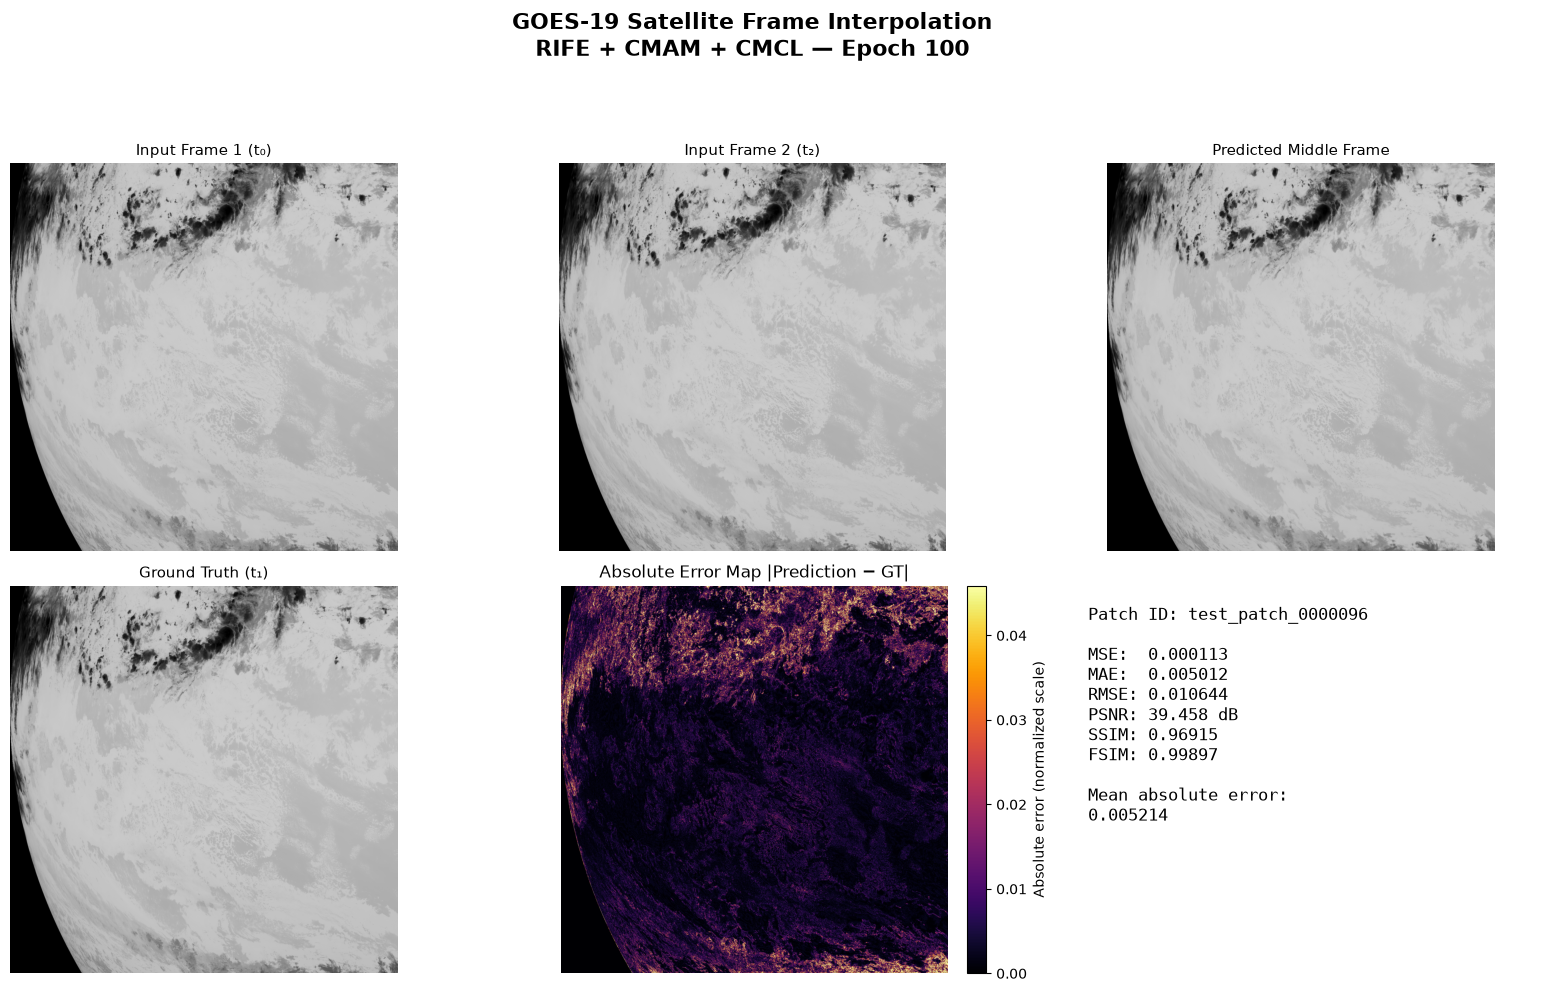

Saved PNG: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/GOES19_RIFE_CMAM_CMCL_EPOCH100/visualizations/goes19_patch_0096_comparison.png
Saved PDF: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/GOES19_RIFE_CMAM_CMCL_EPOCH100/visualizations/goes19_patch_0096_comparison.pdf


In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# ============================================================
# 1. PATHS
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

RESULT_DIR = (
    PROJECT_DIR
    / "results"
    / "GOES19_RIFE_CMAM_CMCL_EPOCH100"
)

METRICS_CSV = RESULT_DIR / "per_patch_metrics.csv"
PLOT_DIR = RESULT_DIR / "visualizations"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Choose the test patch to visualize (0 = first successful patch)
PATCH_INDEX = 96

# ============================================================
# 2. LOAD EVALUATION RESULTS
# ============================================================

if not METRICS_CSV.exists():
    raise FileNotFoundError(
        f"Metrics CSV not found: {METRICS_CSV}\n"
        "Run your GOES-19 test evaluation first."
    )

df = pd.read_csv(METRICS_CSV)

if df.empty:
    raise RuntimeError("No successful test patches found.")

row = df.iloc[PATCH_INDEX]

print("Patch ID:", row["patch_id"])
print("PSNR:", row["PSNR_dB"], "dB")
print("SSIM:", row["SSIM"])
print("MSE:", row["MSE"])

# ============================================================
# 3. IMAGE LOADER
# ============================================================

def load_grayscale(path):
    path = Path(str(path))

    if not path.exists():
        raise FileNotFoundError(f"Image not found: {path}")

    if path.suffix.lower() == ".npy":
        image = np.load(path)
    elif path.suffix.lower() == ".npz":
        with np.load(path) as data:
            key = "image" if "image" in data.files else data.files[0]
            image = data[key]
    else:
        image = np.asarray(Image.open(path))

    image = np.squeeze(image)

    if image.ndim == 3:
        if image.shape[0] in (1, 3, 4) and image.shape[-1] not in (1, 3, 4):
            image = np.moveaxis(image, 0, -1)

        if image.shape[-1] in (3, 4):
            image = image[..., :3].astype(np.float32)
            image = (
                0.299 * image[..., 0]
                + 0.587 * image[..., 1]
                + 0.114 * image[..., 2]
            )
        elif image.shape[-1] == 1:
            image = image[..., 0]

    if image.ndim != 2:
        raise ValueError(f"Unexpected image shape: {image.shape}")

    return image.astype(np.float32)


def normalize_for_display(image):
    image = image.astype(np.float32)
    finite = np.isfinite(image)

    if not finite.any():
        return np.zeros_like(image)

    values = image[finite]
    low, high = values.min(), values.max()

    if low >= 0 and high <= 1:
        result = image.copy()
    elif low >= 0 and high <= 255:
        result = image / 255.0
    elif low >= 150 and high <= 400:
        result = (image - 200.0) / 120.0
    else:
        result = image.copy()

    return np.clip(np.nan_to_num(result), 0, 1)


# ============================================================
# 4. LOAD BOTH INPUTS, PREDICTION AND GROUND TRUTH
# ============================================================

img0 = normalize_for_display(
    load_grayscale(row["img0_path"])
)

img2 = normalize_for_display(
    load_grayscale(row["img2_path"])
)

gt = normalize_for_display(
    load_grayscale(row["gt_path"])
)

pred_path = Path(str(row["prediction_path"]))

if not pred_path.exists():
    raise FileNotFoundError(
        f"Saved prediction not found: {pred_path}"
    )

pred = normalize_for_display(load_grayscale(pred_path))

if not (img0.shape == img2.shape == gt.shape == pred.shape):
    raise ValueError(
        f"Image shape mismatch: {img0.shape}, {img2.shape}, "
        f"{gt.shape}, {pred.shape}"
    )

# ============================================================
# 5. CALCULATE ERROR MAP
# ============================================================

absolute_error = np.abs(pred - gt)

# Display error in the same normalized image scale.
error_map = absolute_error.copy()

# ============================================================
# 6. SCIENTIFIC VISUALIZATION
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

fig.suptitle(
    "GOES-19 Satellite Frame Interpolation\n"
    "RIFE + CMAM + CMCL — Epoch 100",
    fontsize=16,
    fontweight="bold"
)

# Use a common grayscale range for image comparison.
image_panels = [
    (img0, "Input Frame 1 (t₀)"),
    (img2, "Input Frame 2 (t₂)"),
    (pred, "Predicted Middle Frame"),
    (gt, "Ground Truth (t₁)"),
]

for ax, (image, title) in zip(axes.flat[:4], image_panels):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

im = axes.flat[4].imshow(
    absolute_error,
    cmap="inferno",
    vmin=0,
    vmax=max(float(np.percentile(absolute_error, 99)), 1e-6)
)

axes.flat[4].set_title("Absolute Error Map |Prediction − GT|")
axes.flat[4].axis("off")
fig.colorbar(im, ax=axes.flat[4], fraction=0.046, pad=0.04,
             label="Absolute error (normalized scale)")

# Overlay panel with summary metrics.
axes.flat[5].axis("off")

summary = (
    f"Patch ID: {row['patch_id']}\n\n"
    f"MSE:  {float(row['MSE']):.6f}\n"
    f"MAE:  {float(row['MAE']):.6f}\n"
    f"RMSE: {float(row['RMSE']):.6f}\n"
    f"PSNR: {float(row['PSNR_dB']):.3f} dB\n"
    f"SSIM: {float(row['SSIM']):.5f}\n"
    f"FSIM: {float(row['FSIM']):.5f}\n\n"
    f"Mean absolute error:\n"
    f"{np.mean(absolute_error):.6f}"
)

axes.flat[5].text(
    0.05, 0.95, summary,
    va="top", ha="left",
    fontsize=12,
    family="monospace"
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

png_path = PLOT_DIR / f"goes19_patch_{PATCH_INDEX:04d}_comparison.png"
pdf_path = PLOT_DIR / f"goes19_patch_{PATCH_INDEX:04d}_comparison.pdf"

plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.savefig(pdf_path, bbox_inches="tight")
plt.show()

print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)


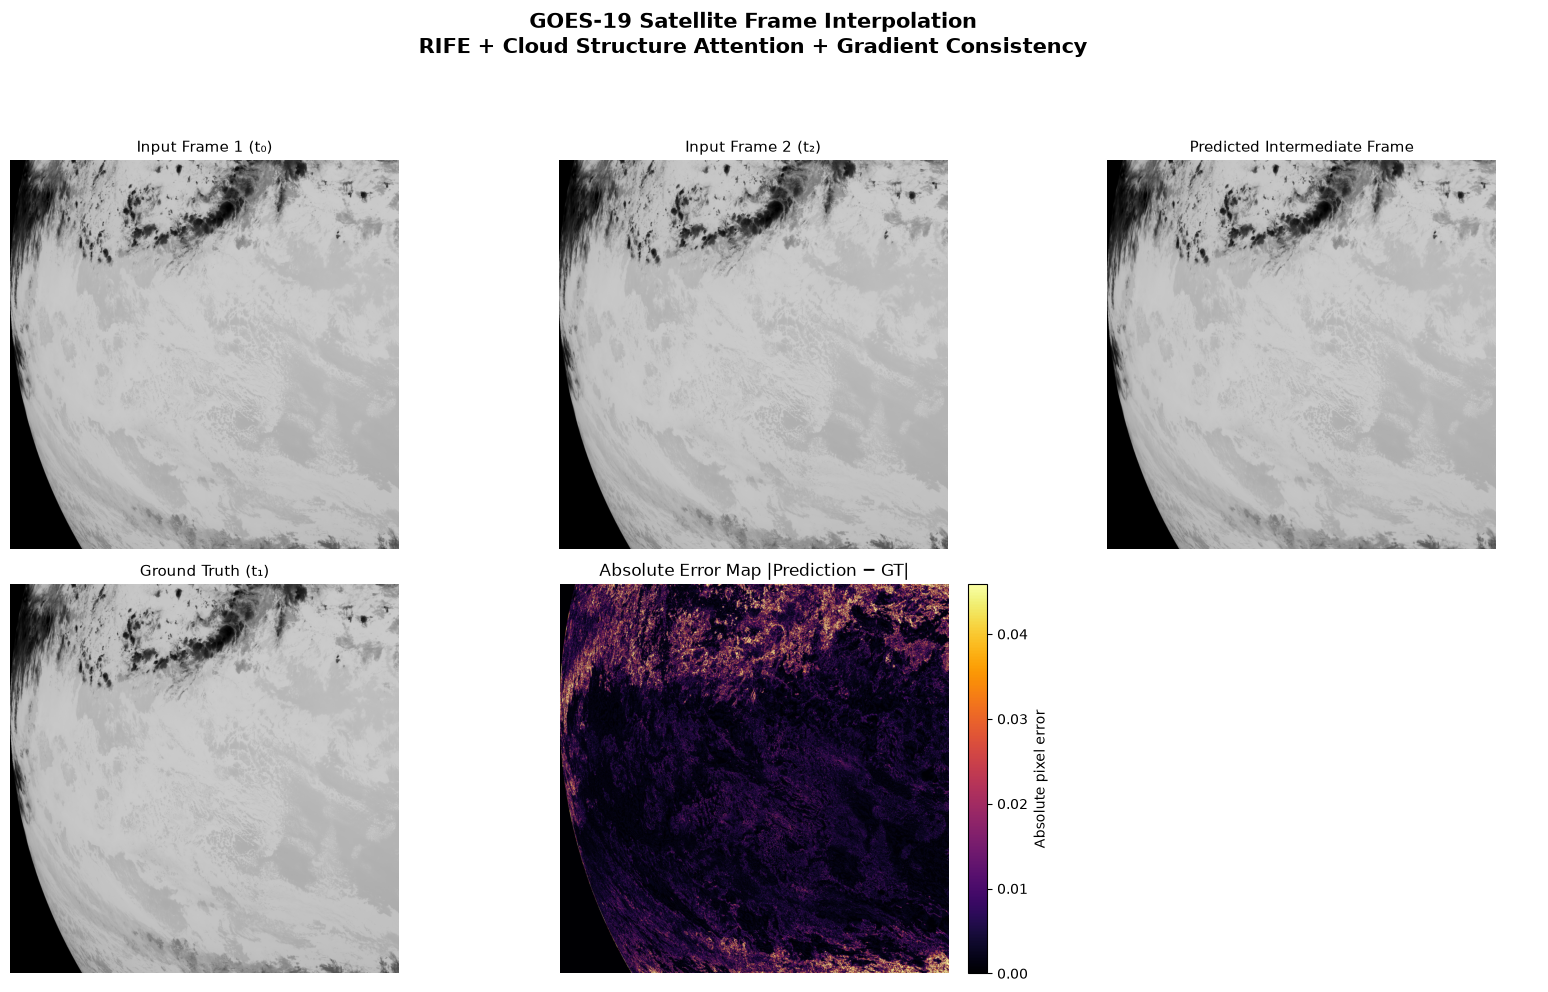

Saved PNG: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/GOES19_RIFE_CMAM_CMCL_EPOCH100/visualizations/patch_96_with_error_map.png
Saved PDF: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/GOES19_RIFE_CMAM_CMCL_EPOCH100/visualizations/patch_96_with_error_map.pdf


In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

RESULT_DIR = (
    PROJECT_DIR / "results" / "GOES19_RIFE_CMAM_CMCL_EPOCH100"
)

METRICS_CSV = RESULT_DIR / "per_patch_metrics.csv"
PLOT_DIR = RESULT_DIR / "visualizations"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(METRICS_CSV)
df["PSNR_dB"] = pd.to_numeric(df["PSNR_dB"], errors="coerce")

# Select the patch with the highest PSNR (patch ID 96 in your CSV)
row = df.loc[df["PSNR_dB"].idxmax()]

def load_image(path):
    path = Path(str(path))

    if path.suffix.lower() == ".npy":
        image = np.load(path)
    elif path.suffix.lower() == ".npz":
        with np.load(path) as data:
            key = "image" if "image" in data.files else data.files[0]
            image = data[key]
    else:
        image = np.asarray(Image.open(path))

    image = np.squeeze(image)

    if image.ndim == 3:
        if image.shape[-1] in (3, 4):
            image = image[..., :3].mean(axis=-1)
        elif image.shape[0] in (1, 3, 4):
            image = image[:3].mean(axis=0)

    image = image.astype(np.float32)
    finite = np.isfinite(image)

    if not finite.any():
        return np.zeros_like(image)

    low, high = image[finite].min(), image[finite].max()

    if low >= 0 and high <= 1:
        pass
    elif low >= 0 and high <= 255:
        image = image / 255.0
    elif low >= 150 and high <= 400:
        image = (image - 200.0) / 120.0

    return np.clip(np.nan_to_num(image), 0, 1)

# Load images
img0 = load_image(row["img0_path"])
img2 = load_image(row["img2_path"])
pred = load_image(row["prediction_path"])
gt = load_image(row["gt_path"])

if not (img0.shape == img2.shape == pred.shape == gt.shape):
    raise ValueError("Image dimensions do not match.")

# Absolute error map
error_map = np.abs(pred - gt)

# Scientific visualization
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

fig.suptitle(
    "GOES-19 Satellite Frame Interpolation\n"
    "RIFE + Cloud Structure Attention + Gradient Consistency",
    fontsize=15,
    fontweight="bold"
)

panels = [
    (img0, "Input Frame 1 (t₀)"),
    (img2, "Input Frame 2 (t₂)"),
    (pred, "Predicted Intermediate Frame"),
    (gt, "Ground Truth (t₁)")
]

for ax, (image, title) in zip(axes.flat[:4], panels):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

# Error map
error_limit = max(float(np.percentile(error_map, 99)), 1e-6)

im = axes.flat[4].imshow(
    error_map,
    cmap="inferno",
    vmin=0,
    vmax=error_limit
)

axes.flat[4].set_title("Absolute Error Map |Prediction − GT|")
axes.flat[4].axis("off")

fig.colorbar(
    im,
    ax=axes.flat[4],
    fraction=0.046,
    pad=0.04,
    label="Absolute pixel error"
)

# Empty sixth panel
axes.flat[5].axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.93])

png_path = PLOT_DIR / "patch_96_with_error_map.png"
pdf_path = PLOT_DIR / "patch_96_with_error_map.pdf"

plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.savefig(pdf_path, bbox_inches="tight")
plt.show()
plt.close()

print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)
